# Maitree Mody — ECI versus GDP per capita

**Research question: Do countries with higher ECI have higher GDP per capita?**

This is the central empirical claim behind ECI (Hidalgo & Hausmann 2009; *Atlas of Economic Complexity*): complexity is strongly correlated with income, and natural-resource exporters sit above the line. So this is a **validation check**, not a new finding. The question here: does the lab's own ECI reproduce the pattern?

We compare four country measures against log GDP per capita (PPP, constant 2021 international $, World Bank `NY.GDP.PCAP.PP.KD`):

1. **ECI, HS4 products**: about 1,220 HS 4-digit products built from `data/raw/<year>_mega.csv`. Closest to Harvard's method.
2. **ECI, 17 groups**: the lab's cleaned industry groups (`data/cleaned/<year>clean.csv`) without the overlapping High-complexity Products group, sign fixed.
3. **ECI, lab notebook as-is**: replicates `compute_eci` in `code/current/Spring2026.ipynb`.
4. **Diversity**: number of HS4 products with RCA ≥ 1. A simple benchmark: does ECI add anything beyond counting products?

## Method

Countries with ≥ $1B goods exports. Aggregates (EU-28, "nes" areas) removed. Taiwan is kept (Comtrade code 490). The World Bank doesn't cover Taiwan, so it drops at the merge. Primary year: 2019. 2020–2022 are repeats, and 2023 is shown only for completeness (its raw exports are inflated, `docs/KNOWN-ISSUES.md` D1). Regressions use HC1 robust standard errors.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
HERE = Path.cwd()
sys.path.insert(0, str(HERE))
from analyze import run
d = run()

# Do countries with higher ECI have higher GDP per capita? — results

## 1. Spearman correlation with log GDP per capita (PPP)

| measure                     |   2019 |   2020 |   2021 |   2022 |   2023 |
|:----------------------------|-------:|-------:|-------:|-------:|-------:|
| Diversity (HS4 RCA count)   |   0.4  |   0.39 |   0.34 |   0.28 |   0.28 |
| ECI, 17 groups (sign fixed) |   0.37 |   0.4  |   0.51 |   0.44 |   0.41 |
| ECI, HS4 products           |   0.78 |   0.81 |   0.77 |   0.78 |   0.77 |
| ECI, lab notebook as-is     |   0.4  |   0.45 |  -0.47 |   0.33 |  -0.38 |

2023 shown for completeness only: its raw export data is inflated (KNOWN-ISSUES D1).

## 2. Regressions, 2019, log GDP per capita (PPP), HC1 standard errors

Common sample: 126 countries with both ECIs, World Bank data and ≥$1B exports.

| model   | formula                              |   n |    r2 |   loo_rmse | b[eci_hs4]      | b[eci_grp]      | b[log_diversity]   | b[resource_share]   | b[resource_dep

## 1. Does higher ECI go with higher income?

Spearman correlation compares country rankings, by year and measure.

In [2]:
corr = pd.read_csv(HERE / 'outputs/correlations.csv')
display(corr.pivot(index='measure', columns='year', values='spearman_rho').round(2))

year,2019,2020,2021,2022,2023
measure,,,,,
Diversity (HS4 RCA count),0.40,0.39,0.34,0.28,0.28
"ECI, 17 groups (sign fixed)",0.37,0.40,0.51,0.44,0.41
"ECI, HS4 products",0.78,0.81,0.77,0.78,0.77
"ECI, lab notebook as-is",0.40,0.45,-0.47,0.33,-0.38


## 2. Picture (2019)

Left: product-level ECI. Right: the lab's 17-group ECI. Red = resource-dependent (≥ 40% of exports are ores, fuels, or precious stones/metals).

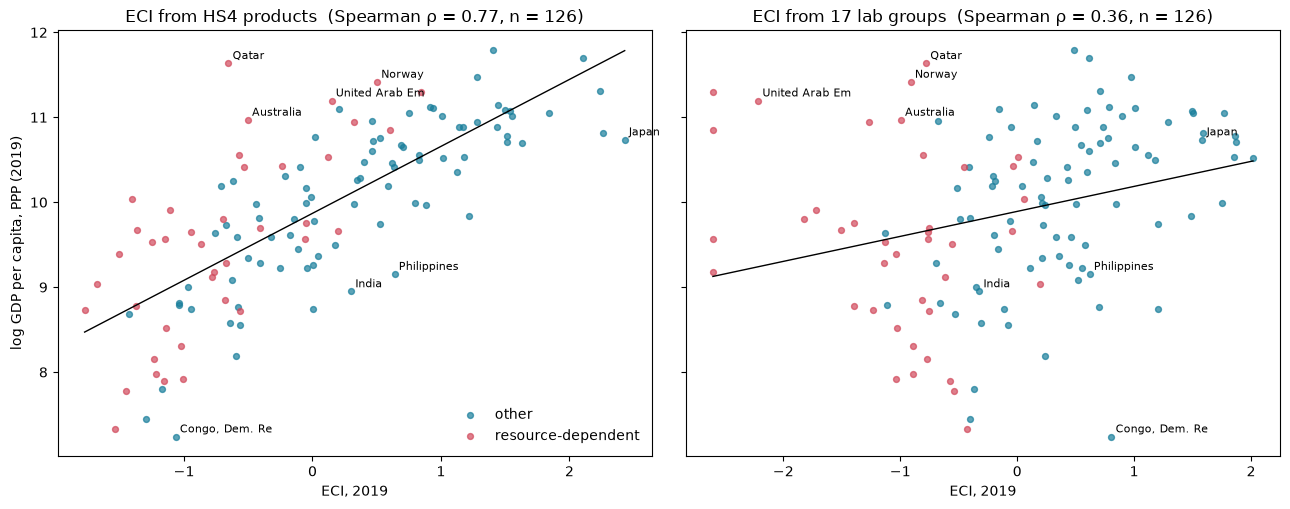

In [3]:
s = d.loc[2019].dropna(subset=['eci_hs4', 'eci_grp', 'log_gdppc'])
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, col, title in [(axes[0], 'eci_hs4', 'ECI from HS4 products'), (axes[1], 'eci_grp', 'ECI from 17 lab groups')]:
    for dep, color, label in [(0, '#187e9b', 'other'), (1, '#d1495b', 'resource-dependent')]:
        t = s[s.resource_dep == dep]
        ax.scatter(t[col], t.log_gdppc, s=18, alpha=.7, color=color, label=label)
    b = np.polyfit(s[col], s.log_gdppc, 1); xs = np.linspace(s[col].min(), s[col].max(), 2)
    ax.plot(xs, np.polyval(b, xs), color='black', lw=1)
    rho = s[col].corr(s.log_gdppc, method='spearman')
    ax.set(title=f'{title}  (Spearman ρ = {rho:.2f}, n = {len(s)})', xlabel='ECI, 2019')
    for name in ['Qatar', 'Norway', 'Australia', 'United Arab Emirates', 'Japan', 'Philippines', 'India', 'Congo, Dem. Rep.']:
        if name in s.index:
            ax.annotate(name[:14], (s.loc[name, col], s.loc[name, 'log_gdppc']), fontsize=8, xytext=(3, 3), textcoords='offset points')
axes[0].set_ylabel('log GDP per capita, PPP (2019)'); axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(HERE / 'outputs/2019_eci_vs_gdppc.png', dpi=130); plt.show()

## 3. Regressions (2019)

- **A vs B:** how much income variation each ECI version explains.
- **C, D:** does ECI beat simple diversity?
- **E, F:** resource exports.

LOO RMSE = leave-one-country-out error in log points, a check of how well each model generalizes to a country it didn't see. It is **not** a forecast: ECI is computed from all countries jointly.

In [4]:
display(pd.read_csv(HERE / 'outputs/regressions_2019.csv').fillna(''))

,model,formula,n,r2,loo_rmse,b[eci_hs4],b[eci_grp],b[log_diversity],b[resource_share],b[resource_dep],b[eci_hs4:resource_dep]
0,A,log_gdppc ~ eci_hs4,126,0.562730,0.686616,+0.79 (p=0.000),,,,,
1,B,log_gdppc ~ eci_grp,126,0.081168,0.995965,,+0.29 (p=0.002),,,,
2,C,log_gdppc ~ log_diversity,126,0.097741,0.990144,,,+0.38 (p=0.002),,,
3,D,log_gdppc ~ eci_hs4 + log_diversity,126,0.603281,0.662028,+0.96 (p=0.000),,-0.31 (p=0.002),,,
4,E,log_gdppc ~ eci_hs4 + resource_share,126,0.632405,0.636371,+0.94 (p=0.000),,,+1.07 (p=0.000),,
5,F,log_gdppc ~ eci_hs4 * resource_dep,126,0.605323,0.664141,+0.84 (p=0.000),,,,+0.62 (p=0.000),+0.30 (p=0.079)


## 4. Who departs from the line?

Residuals from model A (log GDP per capita ~ HS4 ECI). Positive = richer than complexity predicts.

In [5]:
res = pd.read_csv(HERE / 'outputs/2019_residuals.csv', index_col=0)
display(res.tail(10)[::-1].round(2))
display(res.head(10).round(2))

,eci_hs4,eci_grp,gdppc_ppp,resource_share,resid
name,,,,,
Qatar,-0.65,-0.78,113160.97,0.99,2.28
Australia,-0.50,-0.99,58048.62,0.69,1.50
Suriname,-1.41,0.06,22966.74,0.86,1.28
United Arab Emirates,0.15,-2.21,72822.95,0.67,1.21
Norway,0.50,-0.91,90772.90,0.59,1.15
Oman,-0.57,-0.81,38292.39,0.71,1.13
Iceland,0.21,-0.15,65994.99,0.02,1.06
Kazakhstan,-0.53,-0.46,33298.21,0.72,0.96
Azerbaijan,-1.11,-1.72,20101.49,0.92,0.91


,eci_hs4,eci_grp,gdppc_ppp,resource_share,resid
name,,,,,
"Congo, Dem. Rep.",-1.06,0.81,1394.76,0.12,-1.79
Madagascar,-1.29,-0.41,1707.83,0.13,-1.41
Mozambique,-1.54,-0.43,1528.89,0.51,-1.32
Philippines,0.64,0.62,9452.29,0.06,-1.22
Zambia,-0.60,0.23,3591.56,0.05,-1.21
India,0.30,-0.32,7702.18,0.26,-1.16
Rwanda,-1.01,-1.04,2753.54,0.50,-1.16
Ethiopia,-1.17,-0.37,2437.97,0.00,-1.15
West Bank and Gaza,0.00,1.21,6269.89,0.00,-1.13


## 5. Same check on the lab notebook's ECI

The notebook's ECI correlates *negatively* with income in 2021 and 2023. Its sign is set by whichever country appears in the first row of the data file (`compute_eci`: `if vector[0] < 0`), so the whole ranking can flip from year to year. This is worth raising with the team before anyone uses notebook ECI for growth or income work.

In [6]:
nb = corr[corr.measure.str.contains('notebook')].set_index('year')[['n', 'spearman_rho']].round(2)
display(nb)

,n,spearman_rho
year,,
2019,104,0.40
2020,104,0.45
2021,93,-0.47
2022,104,0.33
2023,107,-0.38


## 6. Results and limitations

In [7]:
display(Markdown((HERE / 'outputs/findings.md').read_text()))

# ECI versus GDP per capita — findings

Question: Do countries with higher ECI have higher GDP per capita?

**Yes, when ECI is computed at the product level. Only weakly when it's computed on the lab's 17 industry groups.**

- **Product-level (HS4) ECI** has a Spearman correlation of 0.77–0.81 with log GDP per capita (PPP) in every year 2019–2023. In 2019 it alone explains 56% of cross-country variation in log income (n = 126). One standard deviation more ECI goes with about 2.2× higher GDP per capita (exp(0.79)).
- **The lab's 17-group ECI** (sign fixed) correlates only about 0.36–0.51 (depending on year and sample) and explains 8% (R² = 0.08). It does no better than simply counting products with RCA ≥ 1 (R² = 0.10).
- **The lab notebook's ECI as-is** correlates −0.47 with income in 2021 and −0.38 in 2023. That's the sign-convention problem, not an economic result.
- **ECI beats raw diversity.** Holding product-level ECI fixed, diversity enters negatively (model D). The information is in *which* products a country makes, not how many. This matches Mealy, Farmer & Teytelboym (2019).
- **Resource exporters are richer than their complexity predicts** (Qatar, Australia, UAE, Norway, Oman, Kazakhstan). Average residual +0.23 log points vs −0.11 for others. Adding resource share raises R² from 0.56 to 0.63. This is the known Atlas pattern (and why Harvard's growth projections control for natural-resource exports), reproduced here, not discovered.
- **Poorer than predicted:** mostly low-income African economies plus India and the Philippines. India and the Philippines have mid-range ECI but low income, the "complexity ahead of income" cases Harvard's framework predicts will grow faster. Testing that is a growth question, not this one.

## Interpretation and limits

- **Correlation, not causation.** Rich countries may become complex rather than the reverse, and both may be driven by institutions, human capital or geography. A cross-section can't tell these apart.
- **The 17-group result is mainly a measurement finding.** With 17 groups, the RCA matrix has too little detail to separate countries' capabilities. That matters for the lab's reports, which all use the grouped ECI.
- **Not Harvard's ECI.** The data is exporter-reported only (Harvard reconciles exporter and importer reports), uses whatever HS revision each country reported, has no population filter, and uses binary RCA (Harvard moved to a continuous measure in 2026). The HS4 top 6 in 2019 (Japan, Korea, Switzerland, Taiwan, Singapore, Germany) match Atlas 10.0's top six, which is reassuring but not a formal check.
- **Resource definition is crude.** HS chapters 26, 27 and 71 miss refined copper (ch. 74), so Zambia and DR Congo show low resource shares. The 40% cutoff is arbitrary. Residual patterns should be rechecked with a better definition.
- **2023 exports are inflated** in the raw pull (KNOWN-ISSUES D1). Its row is for completeness only.
- **Single cross-sections.** Years 2019–2023 aren't independent evidence: the same countries, with very persistent ECI.

## Next steps

1. Download Harvard's published ECI (Atlas data downloads) and correlate it with our HS4 ECI. A formal replication check.
2. Redo the resource definition (add ch. 74–81 refined metals) and see whether the resource residual pattern holds.
3. Panel version: within-country changes in ECI vs changes in income (country fixed effects). This moves toward the "complexity predicts growth" question.
4. Flag the notebook sign issue and the group-vs-product gap to the team.
